# 02 – Descriptive statistics

Describes the sample and shows the raw comparisons behind the models in notebook 03.
Tables go to `output/tables/`, figures to `output/figures/` (PNG).

`has_expansion` = at least one *core* expansion (without promos and generic promo packs, see notebook 01).

In [35]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "output" / "tables"
FIGURES = ROOT / "output" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"  # with expansion, without expansion, notes
BIN_LABELS = ["0", "1", "2-3", "4-9", "10+"]
CONTROLS = ["log_playingtime", "minplayers", "maxplayers_capped", "minage", "log_publisher_size", "self_published"]
THOUSANDS = FuncFormatter(lambda v, _: f"{v:,.0f}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4.5), "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

def save_fig(fig, name):
    for ext in ["png"]:
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300)

games = pd.read_csv(ROOT / "data" / "processed" / "games_clean.csv")
games["expansion_bin"] = pd.Categorical(games["expansion_bin"].astype(str), categories=BIN_LABELS)
complete = games.dropna(subset=(["log_owned"] + CONTROLS))
print(f"{len(games):,} games")
print(f"{games['has_expansion'].sum():,} with an expansion")
print(f"{len(complete):,} with complete data on all controls (estimation sample)")

19,545 games
4,344 with an expansion
17,777 with complete data on all controls (estimation sample)


## Table 1 - Summary statistics

The N column shows missing values per variable. The last four columns compare games with and without
an expansion.

In [36]:
VARIABLES = {
    "owned": "Owned (installed base)",
    "n_expansions": "Number of expansions (core)",
    "n_expansions_all": "Number of expansions (all listed)",
    "has_expansion": "Has expansion (0/1)",
    "planned_expansion_genre": "Planned-expansion genre (0/1)",
    "age": "Age in 2022 (years)",
    "playingtime_capped": "Playing time (min, capped)",
    "minplayers": "Min. players",
    "maxplayers_capped": "Max. players (capped)",
    "minage": "Min. age",
    "publisher_size": "Publisher size (games in sample)",
    "self_published": "Self-/web-published (0/1)",
    "average": "Average rating",
    "users_rated": "Number of ratings",
}

table_summary_statistics = games[list(VARIABLES)].agg(["count", "mean", "std", "median", "min", "max"]).T
table_summary_statistics.columns = ["N", "Mean", "SD", "Median", "Min", "Max"]
by_group = games.groupby("has_expansion")[list(VARIABLES)]
for stat in ["mean", "median"]:
    values = by_group.agg(stat).T
    table_summary_statistics[f"{stat.title()}, with expansion"] = values[1]
    table_summary_statistics[f"{stat.title()}, without expansion"] = values[0]
table_summary_statistics.index = table_summary_statistics.index.map(VARIABLES)
table_summary_statistics = table_summary_statistics.round(2)

table_summary_statistics.to_csv(TABLES / "table_summary_statistics.csv")
table_summary_statistics

,N,Mean,SD,Median,Min,Max,"Mean, with expansion","Mean, without expansion","Median, with expansion","Median, without expansion"
Owned (installed base),19545.0,1539.50,5595.26,328.00,2.00,168364.00,4212.23,775.72,910.00,265.00
Number of expansions (core),19545.0,1.16,7.50,0.00,0.00,525.00,5.22,0.00,2.00,0.00
Number of expansions (all listed),19545.0,1.43,8.09,0.00,0.00,525.00,6.14,0.09,2.00,0.00
Has expansion (0/1),19545.0,0.22,0.42,0.00,0.00,1.00,1.00,0.00,1.00,0.00
Planned-expansion genre (0/1),19545.0,0.23,0.42,0.00,0.00,1.00,0.30,0.20,0.00,0.00
Age in 2022 (years),19545.0,15.72,12.60,11.00,3.00,72.00,11.94,16.80,8.00,13.00
"Playing time (min, capped)",18859.0,76.17,92.44,45.00,1.00,600.00,87.27,72.91,60.00,45.00
Min. players,19508.0,2.04,0.67,2.00,1.00,10.00,1.95,2.07,2.00,2.00
Max. players (capped),19399.0,5.03,3.85,4.00,1.00,33.00,5.11,5.00,4.00,4.00
Min. age,18387.0,10.20,2.78,10.00,1.00,25.00,11.23,9.91,12.00,10.00


## Table 2 - Correlations of the model variables

In [37]:
CORR_LABELS = {
    "log_owned": "log(1 + owned)",
    "has_expansion": "Has expansion",
    "log_n_expansions": "log(1 + expansions)",
    "planned_expansion_genre": "Planned-expansion genre",
    "log_playingtime": "log(playing time)",
    "minplayers": "Min. players",
    "maxplayers_capped": "Max. players (capped)",
    "minage": "Min. age",
    "log_publisher_size": "log(publisher size)",
    "self_published": "Self-/web-published",
    "average": "Average rating",
}

table_correlations = games[list(CORR_LABELS)].corr().rename(index=CORR_LABELS, columns=CORR_LABELS)
table_correlations = table_correlations.round(2)

table_correlations.to_csv(TABLES / "table_correlations.csv")
table_correlations

,log(1 + owned),Has expansion,log(1 + expansions),Planned-expansion genre,log(playing time),Min. players,Max. players (capped),Min. age,log(publisher size),Self-/web-published,Average rating
log(1 + owned),1.00,0.37,0.39,0.01,0.15,-0.06,-0.00,0.19,0.24,-0.11,0.33
Has expansion,0.37,1.00,0.82,0.10,0.15,-0.07,0.01,0.20,-0.07,-0.01,0.30
log(1 + expansions),0.39,0.82,1.00,0.16,0.15,-0.08,0.02,0.20,-0.04,-0.02,0.31
Planned-expansion genre,0.01,0.10,0.16,1.00,0.53,-0.19,-0.22,0.31,0.15,-0.06,0.29
log(playing time),0.15,0.15,0.15,0.53,1.00,-0.08,-0.11,0.53,0.09,-0.07,0.37
Min. players,-0.06,-0.07,-0.08,-0.19,-0.08,1.00,0.30,0.04,0.01,-0.02,-0.15
Max. players (capped),-0.00,0.01,0.02,-0.22,-0.11,0.30,1.00,0.00,-0.05,0.01,-0.13
Min. age,0.19,0.20,0.20,0.31,0.53,0.04,0.00,1.00,-0.06,0.01,0.31
log(publisher size),0.24,-0.07,-0.04,0.15,0.09,0.01,-0.05,-0.06,1.00,-0.35,-0.06
Self-/web-published,-0.11,-0.01,-0.02,-0.06,-0.07,-0.02,0.01,0.01,-0.35,1.00,0.03


## Table 3 - Installed base by number of expansions

In [38]:
table_by_expansion_bin = games.groupby("expansion_bin", observed=False)["owned"].agg(
    n_games="size",
    median_owned="median",
    q25_owned=lambda s: s.quantile(0.25),
    q75_owned=lambda s: s.quantile(0.75),
)
table_by_expansion_bin.insert(1, "share_of_games", table_by_expansion_bin["n_games"] / len(games))
table_by_expansion_bin.index.name = "n_expansions"
table_by_expansion_bin = table_by_expansion_bin.round(3)

table_by_expansion_bin.to_csv(TABLES / "table_by_expansion_bin.csv")
table_by_expansion_bin

,n_games,share_of_games,median_owned,q25_owned,q75_owned
n_expansions,,,,,
0,15201,0.778,265.0,135.00,640.0
1,1999,0.102,627.0,259.50,1697.5
2-3,1102,0.056,1003.5,383.25,3090.5
4-9,791,0.040,1485.0,458.50,5762.5
10+,452,0.023,2616.0,672.00,9429.0


## Figure 1 – Installed base of games with and without an expansion

Raw comparison behind H1.

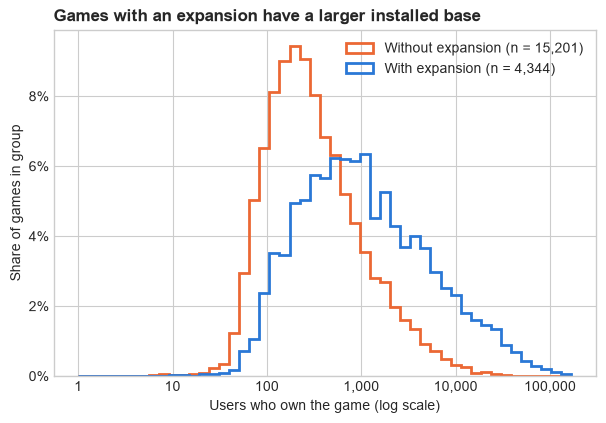

In [39]:
fig, ax = plt.subplots()
bins = np.logspace(0, np.log10(games["owned"].max() + 1), 50)
for value, color, label in [(0, ORANGE, "Without expansion"), (1, BLUE, "With expansion")]:
    owned = games.loc[games["has_expansion"] == value, "owned"] + 1
    ax.hist(owned, bins=bins, weights=np.full(len(owned), 1 / len(owned)), histtype="step",
            linewidth=2, color=color, label=f"{label} (n = {len(owned):,})")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Users who own the game (log scale)")
ax.set_ylabel("Share of games in group")
ax.set_title("Games with an expansion have a larger installed base")
ax.legend()
save_fig(fig, "fig_owned_distribution_by_has_expansion")

## Figure 2 – Installed base by number of expansions

Raw comparison behind H2 (median and interquartile range from Table 3 by_expansion_bin_table).

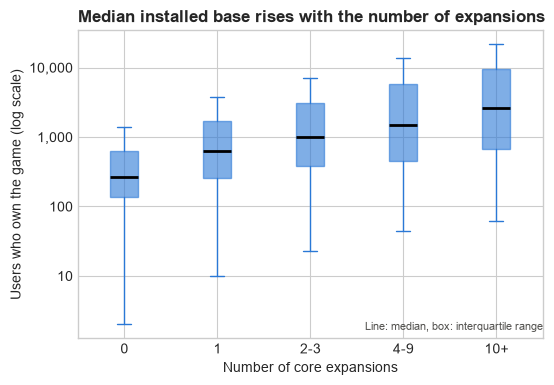

In [40]:
fig, ax = plt.subplots(figsize=(6, 4))
owned_by_bin = [games.loc[games["expansion_bin"] == b, "owned"] for b in BIN_LABELS]
ax.boxplot(owned_by_bin, tick_labels=BIN_LABELS, showfliers=False, widths=0.3,
           patch_artist=True, boxprops={"facecolor": BLUE, "alpha": 0.6, "edgecolor": BLUE},
           medianprops={"color": "black", "linewidth": 2},
           whiskerprops={"color": BLUE}, capprops={"color": BLUE})
ax.set_yscale("log")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel("Number of core expansions")
ax.set_ylabel("Users who own the game (log scale)")
ax.set_title("Median installed base rises with the number of expansions")
ax.text(1, 0.02, "Line: median, box: interquartile range", transform=ax.transAxes,
        ha="right", va="bottom", color=GREY, fontsize=8)
save_fig(fig, "fig_owned_by_expansion_bin")

## Figure 3 – Share of games with an expansion by publication period

Newer games receive expansions more often, so a linear age control is not enough. The models therefore
use publication-year fixed effects, which absorb both game age and era. Periods with fewer than 50 games
are not shown since percentages for these periods would not have enough data to be deamed relevant.

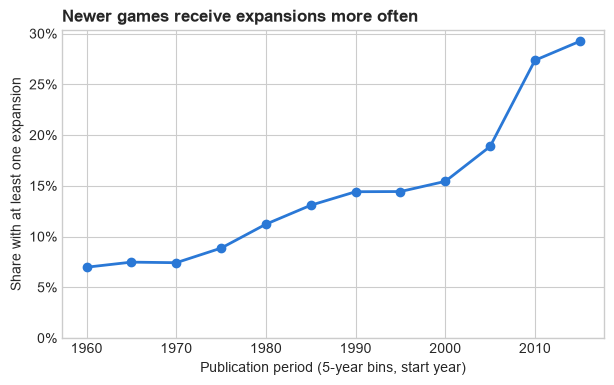

In [41]:
period = games["yearpublished"] // 5 * 5
by_period = games.groupby(period).agg(n_games=("id", "size"), share_with_expansion=("has_expansion", "mean"))
by_period = by_period[by_period["n_games"] >= 50]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by_period.index, by_period["share_with_expansion"], color=BLUE, linewidth=2, marker="o")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, None)
ax.set_xlabel("Publication period (5-year bins, start year)")
ax.set_ylabel("Share with at least one expansion")
ax.set_title("Newer games receive expansions more often")
save_fig(fig, "fig_share_expansion_by_period")